# Hồi quy tuyến tính (Linear Regression) — minh họa và chạy mã

Notebook này đi theo thứ tự các mục của tài liệu *Linear Regression*: từ ví dụ **5 căn nhà**, mô hình và hàm mất mát MSE, Gradient Descent (từng bước, tốc độ học, chuẩn hóa), phương trình chuẩn, biến đổi đặc trưng và quá khớp, MAE, điều chuẩn Ridge/Lasso, cho tới cài đặt và so sánh với scikit-learn.

**Cách dùng:** chạy lần lượt từ trên xuống (`Shift + Enter`). Mỗi mục có phần giải thích, mã và kết quả. Bạn nên thử đổi các tham số được đánh dấu **Thử nghiệm** để quan sát.

| Mục | Nội dung |
| --- | --- |
| 1–2 | Dữ liệu, mô hình tuyến tính, sai số và MSE |
| 3 | Hình dạng hàm mất mát |
| 4 | Gradient Descent: tính tay, huấn luyện, chuẩn hóa, tốc độ học |
| 5 | Phương trình chuẩn |
| 6 | Batch, SGD và Mini-batch |
| 7 | Biến đổi đặc trưng và quá khớp |
| 8 | MSE so với MAE |
| 9 | Điều chuẩn Ridge và Lasso |
| 10 | Dữ liệu lớn hơn: huấn luyện và đánh giá |
| 11 | So sánh với scikit-learn |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Dữ liệu xuyên suốt: 5 căn nhà

`x` là diện tích (đơn vị 10 m²), `y` là giá (tỷ đồng). Ta cần một hàm `ŷ = w₀ + w₁x` để dự đoán giá từ diện tích.

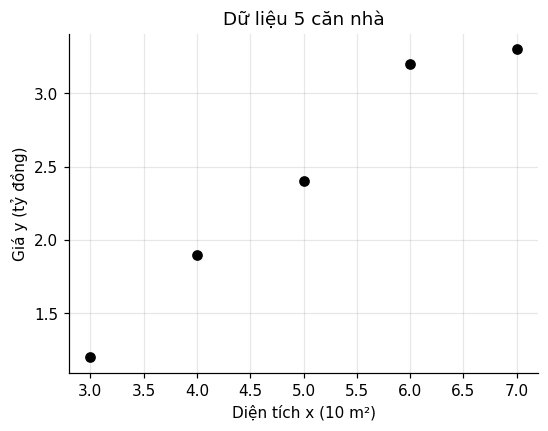

In [2]:
x = np.array([3, 4, 5, 6, 7], dtype=float)
y = np.array([1.2, 1.9, 2.4, 3.2, 3.3])

plt.figure(figsize=(5.5, 4))
plt.scatter(x, y, color="black", zorder=3)
plt.xlabel("Diện tích x (10 m²)"); plt.ylabel("Giá y (tỷ đồng)")
plt.title("Dữ liệu 5 căn nhà"); plt.show()

## 2. Mô hình tuyến tính, sai số và MSE

Mô hình: `ŷ = w₀ + w₁x`. Sai số của mẫu thứ i là `eᵢ = ŷᵢ − yᵢ` (đo theo phương **dọc**), và hàm mất mát là trung bình bình phương sai số:

$$J(\mathbf{w}) = \frac{1}{n}\sum_{i=1}^{n} e_i^2 = \frac{1}{n}\|\mathbf{X}\mathbf{w}-\mathbf{y}\|^2$$

Ta so sánh ba đường thẳng A, B, C. **Thử nghiệm:** thêm đường của riêng bạn vào từ điển `duong`.

Đường A: e = [ 0.1  -0.05  0.   -0.25  0.2 ] | J = 0.0230
Đường B: e = [ 0.05 -0.3  -0.45 -0.9  -0.65] | J = 0.3055
Đường C: e = [0.05 0.1  0.35 0.3  0.95] | J = 0.2255


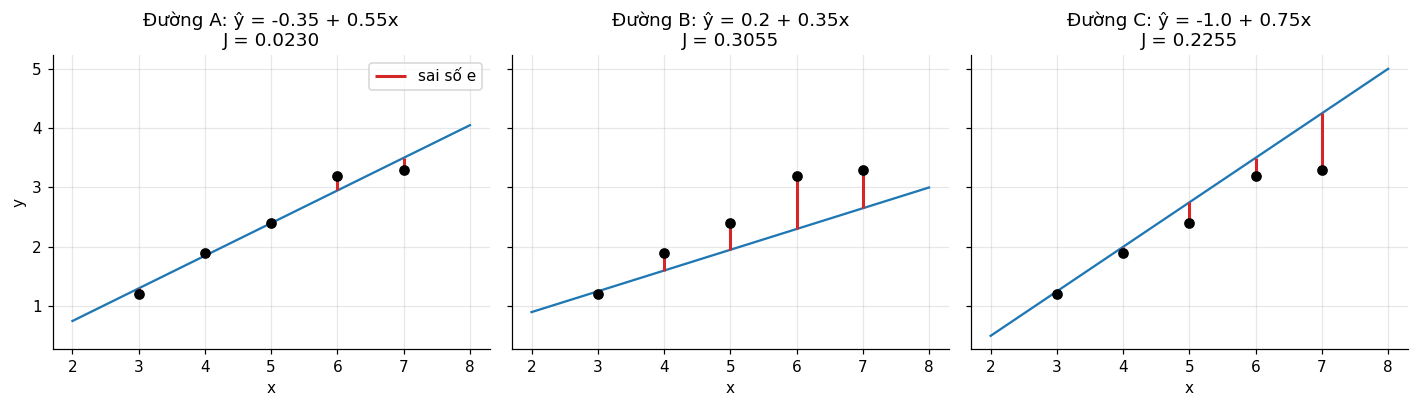

In [3]:
duong = {"A": (-0.35, 0.55), "B": (0.2, 0.35), "C": (-1.0, 0.75)}

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
xx = np.linspace(2, 8, 50)
for ax, (ten, (w0, w1)) in zip(axs, duong.items()):
    y_hat = w0 + w1 * x
    e = y_hat - y
    J = np.mean(e ** 2)
    ax.plot(xx, w0 + w1 * xx, color="tab:blue")
    ax.vlines(x, y, y_hat, color="tab:red", lw=2, label="sai số e")
    ax.scatter(x, y, color="black", zorder=3)
    ax.set_title(f"Đường {ten}: ŷ = {w0} + {w1}x\nJ = {J:.4f}")
    ax.set_xlabel("x")
    print(f"Đường {ten}: e = {np.round(e, 2)} | J = {J:.4f}")
axs[0].set_ylabel("y"); axs[0].legend()
plt.tight_layout(); plt.show()

### Dạng ma trận

Thêm cột 1 vào đầu để gộp hệ số chệch `w₀`: mỗi dòng của `X` là `[1, xᵢ]`. Khi đó `ŷ = Xw`, `e = Xw − y`.

In [4]:
X = np.column_stack([np.ones_like(x), x])     # ma trận đặc trưng n x (d+1)
w = np.array([-0.35, 0.55])
print("X =\n", X)
print("y_hat = Xw =", X @ w)
print("e = Xw - y =", np.round(X @ w - y, 4))
print("J = mean(e^2) =", round(np.mean((X @ w - y) ** 2), 4))

X =
 [[1. 3.]
 [1. 4.]
 [1. 5.]
 [1. 6.]
 [1. 7.]]
y_hat = Xw = [1.3  1.85 2.4  2.95 3.5 ]
e = Xw - y = [ 0.1  -0.05  0.   -0.25  0.2 ]
J = mean(e^2) = 0.023


## 3. Hình dạng của hàm mất mát

Với mỗi cặp `(w₀, w₁)` ta có một giá trị `J`. Vẽ `J` theo hai tham số, ta được một **mặt hình bát**, và đường đồng mức là các hình elip nối những điểm có cùng `J`. Điểm thấp nhất chính là `w*`.

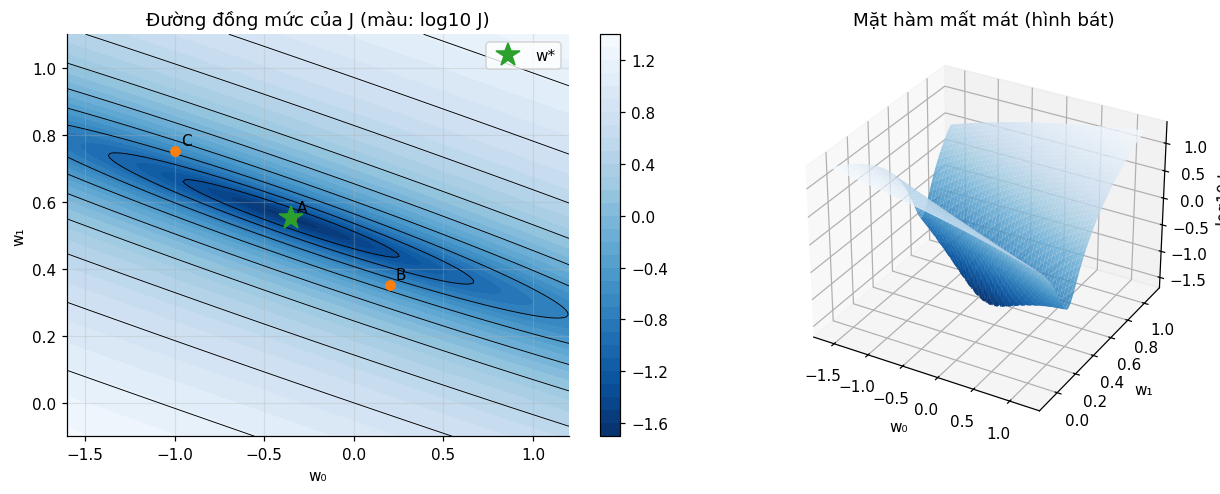

In [5]:
w0g = np.linspace(-1.6, 1.2, 200)
w1g = np.linspace(-0.1, 1.1, 200)
W0, W1 = np.meshgrid(w0g, w1g)
Jg = np.mean((W0[..., None] + W1[..., None] * x - y) ** 2, axis=-1)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
lv = [0.05, 0.1, 0.2, 0.4, 0.8, 1.6, 3.2, 6.4, 12.8]
cs = axs[0].contourf(W0, W1, np.log10(Jg), levels=30, cmap="Blues_r")
axs[0].contour(W0, W1, Jg, levels=lv, colors="k", linewidths=0.6)
for ten, (a, b) in duong.items():
    axs[0].plot(a, b, "o", color="tab:orange"); axs[0].annotate(ten, (a, b), xytext=(4, 4), textcoords="offset points")
axs[0].plot(-0.35, 0.55, "*", color="tab:green", ms=16, label="w*")
axs[0].set_xlabel("w₀"); axs[0].set_ylabel("w₁"); axs[0].set_title("Đường đồng mức của J (màu: log10 J)"); axs[0].legend()
fig.colorbar(cs, ax=axs[0])

axs[1].remove()
ax3 = fig.add_subplot(1, 2, 2, projection="3d")
ax3.plot_surface(W0, W1, np.log10(Jg), cmap="Blues_r", alpha=0.85)
ax3.set_xlabel("w₀"); ax3.set_ylabel("w₁"); ax3.set_zlabel("log10 J"); ax3.set_title("Mặt hàm mất mát (hình bát)")
plt.tight_layout(); plt.show()

## 4. Gradient Descent

### 4.1. Các hàm cơ bản (đúng như mục 6.1 của tài liệu)

| Ký hiệu toán | Mã Python |
| --- | --- |
| Dự đoán `ŷ = Xw` | `Xb @ w` |
| Sai số `e = Xw − y` | `Xb @ w - y` |
| Mất mát `J = (1/n)‖e‖²` | `np.mean(e ** 2)` |
| Gradient `∇J = (2/n) Xᵀe` | `(2 / n) * Xb.T @ e` |
| Cập nhật `w ← w − η∇J` | `w = w - eta * grad` |

In [6]:
def them_bias(X):
    """Thêm cột 1 vào đầu ma trận đặc trưng: (n, d) -> (n, d+1)."""
    return np.hstack([np.ones((X.shape[0], 1)), X])

def du_doan(Xb, w):
    return Xb @ w

def mse(Xb, y, w):
    e = Xb @ w - y
    return np.mean(e ** 2)

def gradient(Xb, y, w):
    n = len(y)
    return (2 / n) * Xb.T @ (Xb @ w - y)

def huan_luyen_gd(Xb, y, eta=0.02, t_max=1000, eps=1e-12):
    """Gradient Descent toàn bộ dữ liệu. Trả về w cuối và lịch sử J."""
    w = np.zeros(Xb.shape[1])
    lich_su = [mse(Xb, y, w)]
    for t in range(t_max):
        w = w - eta * gradient(Xb, y, w)
        lich_su.append(mse(Xb, y, w))
        if abs(lich_su[-2] - lich_su[-1]) < eps:
            break
    return w, lich_su

def phuong_trinh_chuan(Xb, y):
    """Nghiệm đóng: giải (X^T X) w = X^T y."""
    return np.linalg.solve(Xb.T @ Xb, Xb.T @ y)

X_nha = x.reshape(-1, 1)
Xb_nha = them_bias(X_nha)
y_nha = y

### 4.2. Hai lần lặp tính từng pha

Mỗi lần lặp gồm bốn pha: (1) dự đoán và sai số, (2) mất mát, (3) gradient, (4) cập nhật. Với `w = 0` và `η = 0,02`, kết quả phải khớp ví dụ tính tay ở mục 3.5: `J: 6,388 → 0,1242 → 0,0382`.

In [7]:
eta = 0.02
w = np.zeros(2)
for t in range(1, 3):
    print(f"===== Lần lặp {t} =====")
    y_hat = Xb_nha @ w;  e = y_hat - y_nha
    print("1) y_hat =", np.round(y_hat, 4), "\n   e     =", np.round(e, 4))
    print("2) J(w)  =", round(np.mean(e ** 2), 4))
    g = (2 / len(y_nha)) * Xb_nha.T @ e
    print("3) grad  =", np.round(g, 4))
    w = w - eta * g
    print("4) w mới =", np.round(w, 5), "| J mới =", round(mse(Xb_nha, y_nha, w), 4), "\n")

===== Lần lặp 1 =====
1) y_hat = [0. 0. 0. 0. 0.] 
   e     = [-1.2 -1.9 -2.4 -3.2 -3.3]
2) J(w)  = 6.388
3) grad  = [ -4.8 -26.2]
4) w mới = [0.096 0.524] | J mới = 0.1242 

===== Lần lặp 2 =====
1) y_hat = [1.668 2.192 2.716 3.24  3.764] 
   e     = [0.468 0.292 0.316 0.04  0.464]
2) J(w)  = 0.1242
3) grad  = [0.632 3.056]
4) w mới = [0.0834 0.4629] | J mới = 0.0382 



### 4.3. Huấn luyện đến hội tụ và quỹ đạo của `w`

Ta chạy 1000 lần lặp với `η = 0,02` và vẽ quỹ đạo trên bản đồ đường đồng mức. **Nhận xét:** `J` giảm rất nhanh ở những bước đầu rồi chậm lại; `w` còn chưa chạm `w* = (−0,35; 0,55)` sau 1000 bước vì thung lũng hẹp và dài.

w* (phương trình chuẩn) = [-0.35  0.55]
GD sau 1000 lần lặp     = [-0.3252  0.5454] | J = 0.023


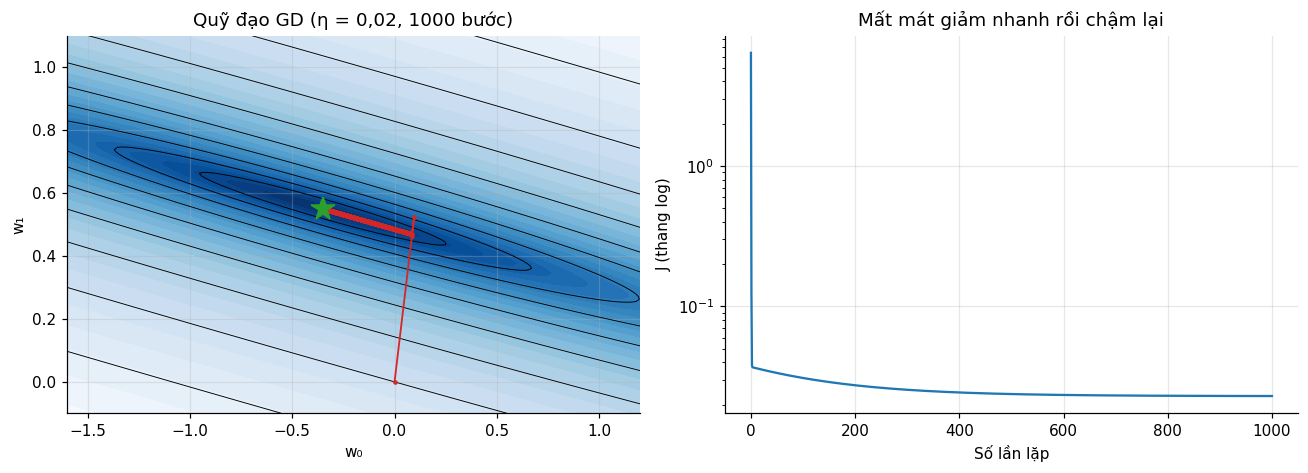

In [8]:
def gd_quy_dao(Xb, y, eta, T):
    """Trả về mảng (T+1, d+1) các w qua từng bước."""
    w = np.zeros(Xb.shape[1]); ws = [w.copy()]
    for _ in range(T):
        w = w - eta * gradient(Xb, y, w); ws.append(w.copy())
    return np.array(ws)

def ve_contour(ax, Xb, y, xr, yr, ws=None, w_opt=None, titles=""):
    a, b = np.meshgrid(np.linspace(*xr, 160), np.linspace(*yr, 160))
    J = np.mean((a[..., None] * Xb[:, 0] + b[..., None] * Xb[:, 1] - y) ** 2, axis=-1)
    ax.contourf(a, b, np.log10(J + 0.01), levels=30, cmap="Blues_r")
    ax.contour(a, b, J, levels=[0.05, 0.1, 0.2, 0.4, 0.8, 1.6, 3.2, 6.4, 12.8], colors="k", linewidths=0.6)
    if ws is not None: ax.plot(ws[:, 0], ws[:, 1], ".-", color="tab:red", ms=4, lw=1.2)
    if w_opt is not None: ax.plot(*w_opt, "*", color="tab:green", ms=16)
    ax.set_xlim(xr); ax.set_ylim(yr); ax.set_xlabel("w₀"); ax.set_ylabel("w₁"); ax.set_title(titles)

w_opt = phuong_trinh_chuan(Xb_nha, y_nha)
w_gd, J_hist = huan_luyen_gd(Xb_nha, y_nha, eta=0.02, t_max=1000, eps=0)
print("w* (phương trình chuẩn) =", w_opt)
print("GD sau 1000 lần lặp     =", w_gd, "| J =", round(J_hist[-1], 4))

ws = gd_quy_dao(Xb_nha, y_nha, 0.02, 1000)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
ve_contour(axs[0], Xb_nha, y_nha, (-1.6, 1.2), (-0.1, 1.1), ws, w_opt, "Quỹ đạo GD (η = 0,02, 1000 bước)")
axs[1].semilogy(J_hist); axs[1].set_xlabel("Số lần lặp"); axs[1].set_ylabel("J (thang log)"); axs[1].set_title("Mất mát giảm nhanh rồi chậm lại")
plt.tight_layout(); plt.show()

### 4.4. Chuẩn hóa đặc trưng

Chuẩn hóa `z = (x − x̄)/σ` làm hàm mất mát gần **tròn** hơn nên Gradient Descent đi thẳng tới đích. Sau khi huấn luyện ở thang `z`, ta quy về thang gốc bằng
`w₁ = w₁′/σ`, `w₀ = w₀′ − w₁′·x̄/σ`.

Sau chuẩn hóa: w' = [2.4    0.7778] | số lần lặp = 17 | J = 0.023
Quy về thang đo gốc : w = [-0.35  0.55]   (khớp w* = [-0.35  0.55] )


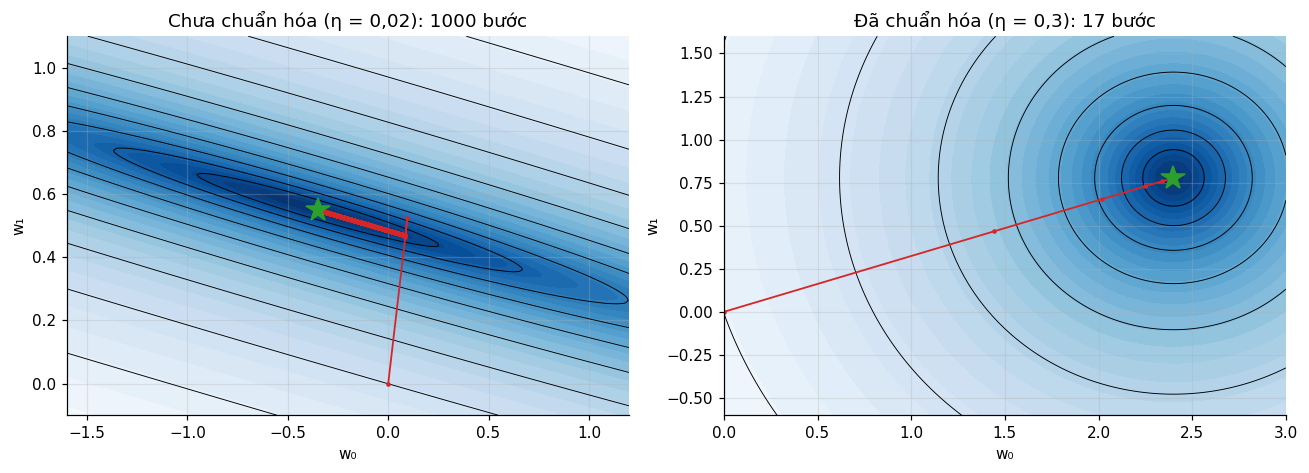

In [9]:
x_tb, x_sd = X_nha.mean(axis=0), X_nha.std(axis=0)
Xs = them_bias((X_nha - x_tb) / x_sd)
w_s, J_s = huan_luyen_gd(Xs, y_nha, eta=0.3, t_max=1000)
print("Sau chuẩn hóa: w' =", np.round(w_s, 4), "| số lần lặp =", len(J_s) - 1, "| J =", round(J_s[-1], 4))
w_goc = np.array([w_s[0] - w_s[1] * x_tb[0] / x_sd[0], w_s[1] / x_sd[0]])
print("Quy về thang đo gốc : w =", np.round(w_goc, 4), "  (khớp w* =", w_opt, ")")

ws_s = gd_quy_dao(Xs, y_nha, 0.3, 17)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
ve_contour(axs[0], Xb_nha, y_nha, (-1.6, 1.2), (-0.1, 1.1), ws, w_opt, "Chưa chuẩn hóa (η = 0,02): 1000 bước")
ve_contour(axs[1], Xs, y_nha, (0, 3), (-0.6, 1.6), ws_s, (2.4, 0.7778), "Đã chuẩn hóa (η = 0,3): 17 bước")
plt.tight_layout(); plt.show()

### 4.5. Vai trò của tốc độ học η

- η quá nhỏ: hội tụ rất chậm.
- η vừa phải: hội tụ nhanh.
- η quá lớn: dao động hoặc **phân kỳ** (J tăng vô hạn).

Với hồi quy tuyến tính ta tính được ngưỡng ổn định: GD hội tụ khi `η < 2/λ_max(H)`, trong đó `H = (2/n)XᵀX` là Hessian của MSE.

λ_max(H) = 55.857  =>  η_max = 2/λ_max = 0.0358


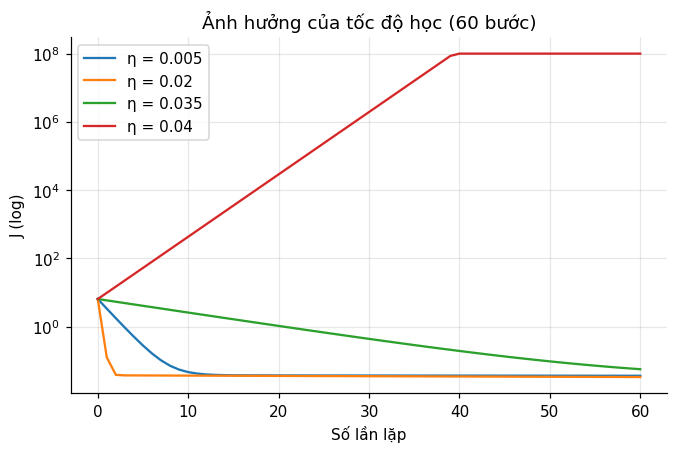

In [10]:
H = (2 / len(y_nha)) * Xb_nha.T @ Xb_nha
lam_max = np.linalg.eigvalsh(H).max()
print(f"λ_max(H) = {lam_max:.3f}  =>  η_max = 2/λ_max = {2 / lam_max:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.2))
for eta in [0.005, 0.02, 0.035, 0.04]:
    _, Jh = huan_luyen_gd(Xb_nha, y_nha, eta=eta, t_max=60, eps=0)
    ax.semilogy(np.clip(Jh, 1e-4, 1e8), label=f"η = {eta}")
ax.set_xlabel("Số lần lặp"); ax.set_ylabel("J (log)"); ax.legend(); ax.set_title("Ảnh hưởng của tốc độ học (60 bước)")
plt.show()

## 5. Phương trình chuẩn: giải trực tiếp

Đặt gradient bằng 0: `XᵀX w = Xᵀy`, nên `w* = (XᵀX)⁻¹Xᵀy`. Trong mã ta dùng `np.linalg.solve` thay vì tính nghịch đảo vì nhanh hơn và chính xác hơn.

In [11]:
XtX, Xty = Xb_nha.T @ Xb_nha, Xb_nha.T @ y_nha
print("XᵀX =\n", XtX, "\nXᵀy =", Xty, "\ndet(XᵀX) =", round(np.linalg.det(XtX), 3))
w_pt = phuong_trinh_chuan(Xb_nha, y_nha)
print("\nw* =", w_pt, "| J =", round(mse(Xb_nha, y_nha, w_pt), 4))

# Ý nghĩa hình học: sai số tại w* vuông góc với mọi cột của X (Xᵀe = 0)
e_opt = Xb_nha @ w_pt - y_nha
print("Xᵀe tại w* =", np.round(Xb_nha.T @ e_opt, 10), " (≈ 0)")

XᵀX =
 [[  5.  25.]
 [ 25. 135.]] 
Xᵀy = [12.  65.5] 
det(XᵀX) = 50.0

w* = [-0.35  0.55] | J = 0.023
Xᵀe tại w* = [-0.  0.]  (≈ 0)


## 6. Ba biến thể: Batch, SGD và Mini-batch

- **Batch GD:** mỗi bước dùng toàn bộ n mẫu (gradient chính xác, mỗi bước tốn kém).
- **SGD:** mỗi bước dùng 1 mẫu (rẻ nhưng nhiễu).
- **Mini-batch:** mỗi bước dùng một lô nhỏ (cân bằng).

Ta so sánh trên 300 căn nhà mô phỏng (hai đặc trưng, đã chuẩn hóa). Dữ liệu này cũng dùng ở các mục 10 và 11.

In [12]:
rng = np.random.default_rng(42)
n = 300
dien_tich = rng.uniform(30, 120, n)            # x1: m²
khoang_cach = rng.uniform(0.5, 15, n)          # x2: km tới trung tâm
gia = 0.8 + 0.045 * dien_tich - 0.08 * khoang_cach + rng.normal(0, 0.4, n)   # y: tỷ đồng
X = np.column_stack([dien_tich, khoang_cach])
print("X:", X.shape, "| y:", gia.shape)
print("y trung bình = %.2f, độ lệch chuẩn = %.2f" % (gia.mean(), gia.std()))

idx = rng.permutation(n)
n_tr = int(0.8 * n)
tr, te = idx[:n_tr], idx[n_tr:]
X_tr, y_tr, X_te, y_te = X[tr], gia[tr], X[te], gia[te]
print("Số mẫu huấn luyện:", len(tr), "| số mẫu kiểm tra:", len(te))

tb, sd = X_tr.mean(axis=0), X_tr.std(axis=0)      # chỉ dùng tập huấn luyện
Xs_tr = them_bias((X_tr - tb) / sd)
Xs_te = them_bias((X_te - tb) / sd)

X: (300, 2) | y: (300,)
y trung bình = 3.47, độ lệch chuẩn = 1.28
Số mẫu huấn luyện: 240 | số mẫu kiểm tra: 60


Batch (240 mẫu/bước)       w = [ 3.467  1.185 -0.363]
Mini-batch (32 mẫu/bước)   w = [ 3.469  1.192 -0.368]
SGD (1 mẫu/bước)           w = [ 3.438  1.232 -0.376]


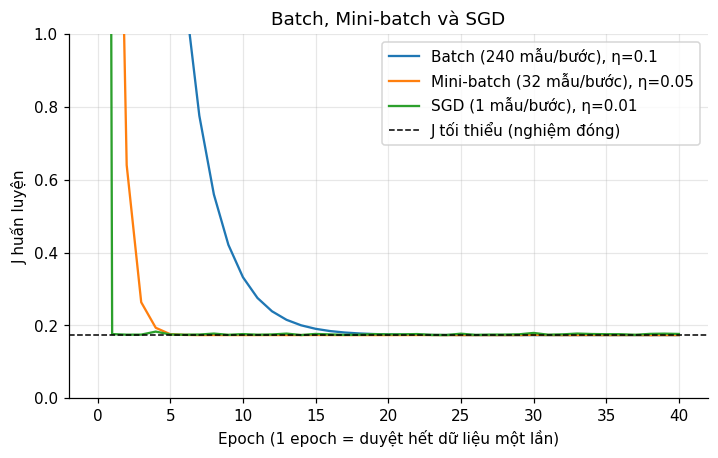

Nghiệm chính xác w* = [ 3.468  1.186 -0.363]


In [13]:
def gd_bien_the(Xb, y, eta, so_epoch, co_lo, seed=0):
    """co_lo = n: Batch, 1: SGD, k: Mini-batch. Trả về J đo trên toàn tập sau mỗi epoch."""
    r = np.random.default_rng(seed)
    w = np.zeros(Xb.shape[1]); J = [mse(Xb, y, w)]
    for _ in range(so_epoch):
        thu_tu = r.permutation(len(y))
        for i in range(0, len(y), co_lo):
            b = thu_tu[i:i + co_lo]
            w = w - eta * gradient(Xb[b], y[b], w)
        J.append(mse(Xb, y, w))
    return w, J

cau_hinh = [("Batch (240 mẫu/bước)", len(y_tr), 0.1), ("Mini-batch (32 mẫu/bước)", 32, 0.05), ("SGD (1 mẫu/bước)", 1, 0.01)]
w_chinh_xac = phuong_trinh_chuan(Xs_tr, y_tr)
fig, ax = plt.subplots(figsize=(7.5, 4.3))
for ten, k, eta in cau_hinh:
    w_, J_ = gd_bien_the(Xs_tr, y_tr, eta, 40, k)
    ax.plot(J_, label=f"{ten}, η={eta}")
    print(f"{ten:26s} w = {np.round(w_, 3)}")
ax.axhline(mse(Xs_tr, y_tr, w_chinh_xac), color="k", ls="--", lw=1, label="J tối thiểu (nghiệm đóng)")
ax.set_ylim(0, 1); ax.set_xlabel("Epoch (1 epoch = duyệt hết dữ liệu một lần)"); ax.set_ylabel("J huấn luyện"); ax.legend()
ax.set_title("Batch, Mini-batch và SGD"); plt.show()
print("Nghiệm chính xác w* =", np.round(w_chinh_xac, 3))

## 7. Biến đổi đặc trưng và quá khớp

Mô hình vẫn **tuyến tính theo tham số** `w` khi ta thêm các đặc trưng `x², x³, …`, nên cùng một công thức huấn luyện nhưng khớp được đường cong. Tuy nhiên bậc quá cao khiến mô hình học cả nhiễu (**quá khớp**): sai số huấn luyện rất thấp nhưng sai số trên dữ liệu mới lại cao.

Ta mô phỏng 10 điểm huấn luyện và 200 điểm kiểm tra từ đường cong `y = 1 + 2,4x − 2,6x²` cộng nhiễu (độ lệch chuẩn 0,25). **Thử nghiệm:** đổi `bac_xem` hoặc số mẫu huấn luyện.

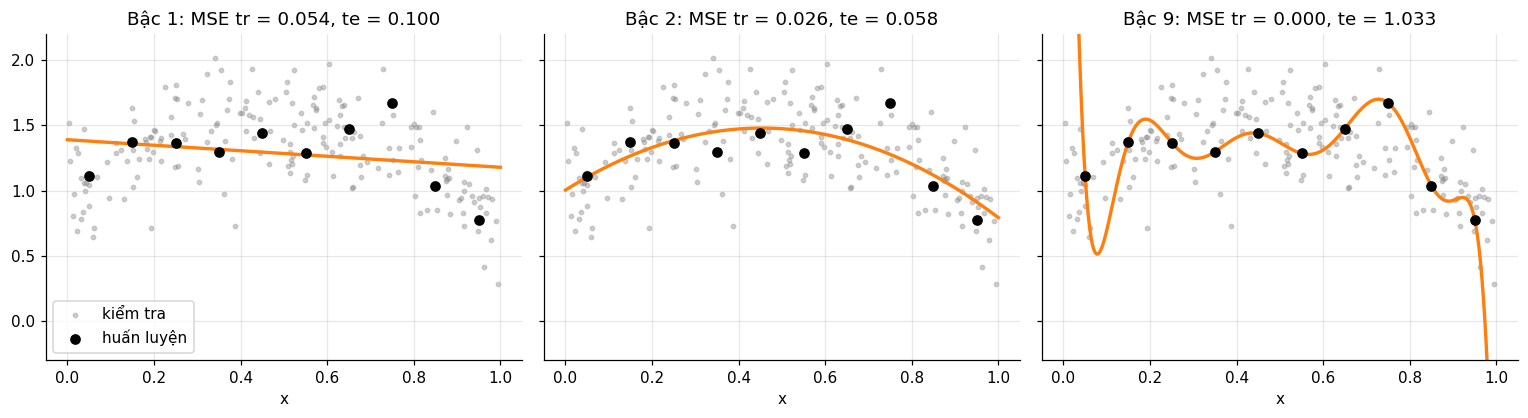

In [14]:
def sinh_du_lieu(n, rng, deu=False):
    xs = (np.arange(n) + 0.5) / n if deu else rng.uniform(0, 1, n)
    return xs, 1 + 2.4 * xs - 2.6 * xs ** 2 + 0.25 * rng.normal(size=n)

def pt_dac_trung(xs, bac):
    return np.column_stack([(2 * xs - 1) ** k for k in range(bac + 1)])   # lũy thừa của t = 2x-1 cho ổn định số

def ridge(Xb, y, lam):
    """Nghiệm đóng (XᵀX + nλP)w = Xᵀy, P không phạt hệ số chệch w0."""
    n_, d1 = Xb.shape
    P = np.eye(d1); P[0, 0] = 0
    return np.linalg.solve(Xb.T @ Xb + n_ * lam * P, Xb.T @ y)

r7 = np.random.default_rng(7)
x_tr7, y_tr7 = sinh_du_lieu(10, r7, deu=True)
x_te7, y_te7 = sinh_du_lieu(200, r7)

bac_xem = [1, 2, 9]
xv = np.linspace(0, 1, 300)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
for ax, bac in zip(axs, bac_xem):
    w7 = ridge(pt_dac_trung(x_tr7, bac), y_tr7, 0.0)
    e_tr = np.mean((pt_dac_trung(x_tr7, bac) @ w7 - y_tr7) ** 2)
    e_te = np.mean((pt_dac_trung(x_te7, bac) @ w7 - y_te7) ** 2)
    ax.scatter(x_te7, y_te7, s=8, color="gray", alpha=0.35, label="kiểm tra")
    ax.scatter(x_tr7, y_tr7, color="black", zorder=3, label="huấn luyện")
    ax.plot(xv, np.clip(pt_dac_trung(xv, bac) @ w7, -1, 3), color="tab:orange", lw=2.2)
    ax.set_ylim(-0.3, 2.2); ax.set_title(f"Bậc {bac}: MSE tr = {e_tr:.3f}, te = {e_te:.3f}"); ax.set_xlabel("x")
axs[0].legend(); plt.tight_layout(); plt.show()

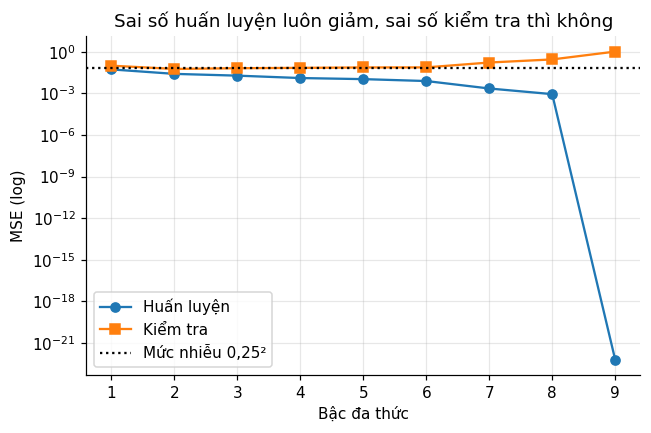

In [15]:
bac_all = range(1, 10)
tr_err, te_err = [], []
for bac in bac_all:
    w7 = ridge(pt_dac_trung(x_tr7, bac), y_tr7, 0.0)
    tr_err.append(np.mean((pt_dac_trung(x_tr7, bac) @ w7 - y_tr7) ** 2))
    te_err.append(np.mean((pt_dac_trung(x_te7, bac) @ w7 - y_te7) ** 2))
plt.figure(figsize=(6.5, 4))
plt.semilogy(bac_all, tr_err, "o-", label="Huấn luyện"); plt.semilogy(bac_all, te_err, "s-", label="Kiểm tra")
plt.axhline(0.25 ** 2, color="k", ls=":", label="Mức nhiễu 0,25²")
plt.xlabel("Bậc đa thức"); plt.ylabel("MSE (log)"); plt.legend(); plt.title("Sai số huấn luyện luôn giảm, sai số kiểm tra thì không"); plt.show()

## 8. MSE so với MAE: ảnh hưởng của điểm ngoại lai

- **MSE** bình phương sai số nên phạt rất nặng sai số lớn, và dễ bị kéo lệch bởi ngoại lai.
- **MAE** dùng `|e|` nên ít nhạy với ngoại lai hơn, nhưng không có nghiệm đóng. Gradient của MAE là `(1/n)Xᵀsign(e)`.

Ta thêm căn nhà thứ sáu ở `x = 8` có giá `6,0` (ngoại lệ). Nghiệm MSE lấy từ phương trình chuẩn; nghiệm MAE tính bằng **bình phương tối thiểu lặp có trọng số** (IRLS), một cách tính khác với GD nhưng cùng cực tiểu.

MSE, không ngoại lệ    w = [-0.35  0.55]
MSE, có ngoại lệ       w = [-1.557  0.829]
MAE, có ngoại lệ       w = [-0.8    0.667]


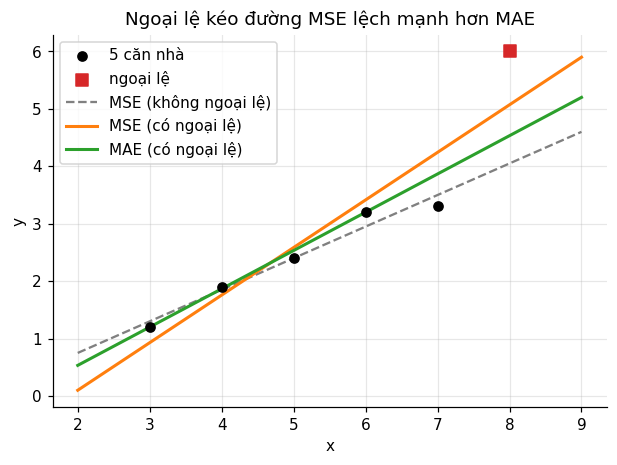

In [16]:
def mae_irls(Xb, y, so_lan=200):
    w = np.linalg.solve(Xb.T @ Xb, Xb.T @ y)
    for _ in range(so_lan):
        k = 1 / np.maximum(np.abs(Xb @ w - y), 1e-8)         # trọng số 1/|e|
        w = np.linalg.solve(Xb.T @ (Xb * k[:, None]), Xb.T @ (y * k))
    return w

y_ngoai = 6.0     # Thử nghiệm: đổi giá của căn nhà ngoại lệ
x6 = np.append(x, 8.0); y6 = np.append(y, y_ngoai)
X6 = np.column_stack([np.ones_like(x6), x6])

w_mse0 = phuong_trinh_chuan(Xb_nha, y_nha)        # MSE, không ngoại lệ
w_mse = phuong_trinh_chuan(X6, y6)                # MSE, có ngoại lệ
w_mae = mae_irls(X6, y6)                          # MAE, có ngoại lệ
for ten, wv in [("MSE, không ngoại lệ", w_mse0), ("MSE, có ngoại lệ", w_mse), ("MAE, có ngoại lệ", w_mae)]:
    print(f"{ten:22s} w = {np.round(wv, 3)}")

xx = np.linspace(2, 9, 50)
plt.figure(figsize=(6.5, 4.4))
plt.scatter(x, y, color="black", zorder=3, label="5 căn nhà")
plt.scatter([8], [y_ngoai], marker="s", color="tab:red", s=60, zorder=3, label="ngoại lệ")
plt.plot(xx, w_mse0[0] + w_mse0[1] * xx, "--", color="gray", label="MSE (không ngoại lệ)")
plt.plot(xx, w_mse[0] + w_mse[1] * xx, color="tab:orange", lw=2, label="MSE (có ngoại lệ)")
plt.plot(xx, w_mae[0] + w_mae[1] * xx, color="tab:green", lw=2, label="MAE (có ngoại lệ)")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.title("Ngoại lệ kéo đường MSE lệch mạnh hơn MAE"); plt.show()

## 9. Điều chuẩn Ridge và Lasso

Điều chuẩn thêm một "chi phí cho sự phức tạp" vào hàm mục tiêu:

$$J_{\text{Ridge}} = \text{MSE} + \lambda\sum_{j\ge1} w_j^2, \qquad J_{\text{Lasso}} = \text{MSE} + \lambda\sum_{j\ge1}|w_j|$$

Hệ số chệch `w₀` không bị phạt. Ridge **co nhỏ** trọng số, Lasso có thể đưa trọng số **về đúng 0** (chọn đặc trưng).

### 9.1. Ridge chữa quá khớp (đa thức bậc 9)

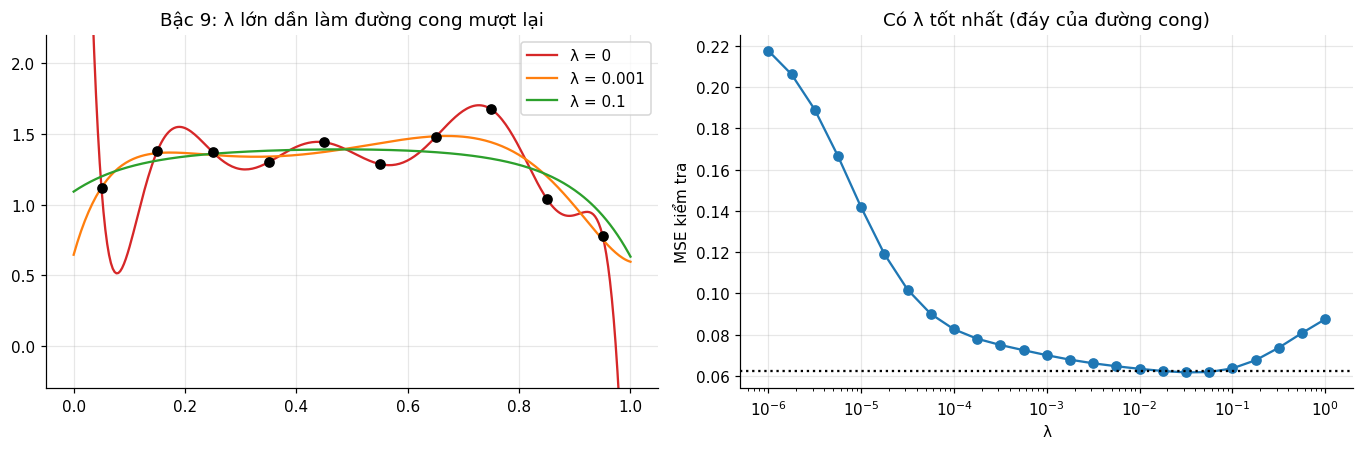

λ tốt nhất ≈ 3.2e-02, MSE kiểm tra = 0.0617


In [17]:
bac = 9
lams = np.logspace(-6, 0, 25)
te_r = []
for lam in lams:
    w7 = ridge(pt_dac_trung(x_tr7, bac), y_tr7, lam)
    te_r.append(np.mean((pt_dac_trung(x_te7, bac) @ w7 - y_te7) ** 2))

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.2))
axs[0].scatter(x_tr7, y_tr7, color="black", zorder=3)
for lam, c in [(0, "tab:red"), (1e-3, "tab:orange"), (1e-1, "tab:green")]:
    w7 = ridge(pt_dac_trung(x_tr7, bac), y_tr7, lam)
    axs[0].plot(xv, np.clip(pt_dac_trung(xv, bac) @ w7, -1, 3), color=c, label=f"λ = {lam}")
axs[0].set_ylim(-0.3, 2.2); axs[0].legend(); axs[0].set_title("Bậc 9: λ lớn dần làm đường cong mượt lại")
axs[1].semilogx(lams, te_r, "o-"); axs[1].axhline(0.25 ** 2, color="k", ls=":")
axs[1].set_xlabel("λ"); axs[1].set_ylabel("MSE kiểm tra"); axs[1].set_title("Có λ tốt nhất (đáy của đường cong)")
plt.tight_layout(); plt.show()
print("λ tốt nhất ≈ %.1e, MSE kiểm tra = %.4f" % (lams[np.argmin(te_r)], min(te_r)))

### 9.2. Lasso chọn đặc trưng

Để thấy hiệu ứng "về đúng 0", ta tạo dữ liệu có **2 đặc trưng thật** và **4 đặc trưng nhiễu** (không liên quan tới `y`), rồi vẽ đường đi của trọng số theo `λ`. (Dữ liệu này chỉ dùng cho minh họa, tách khỏi bộ 300 căn nhà.)

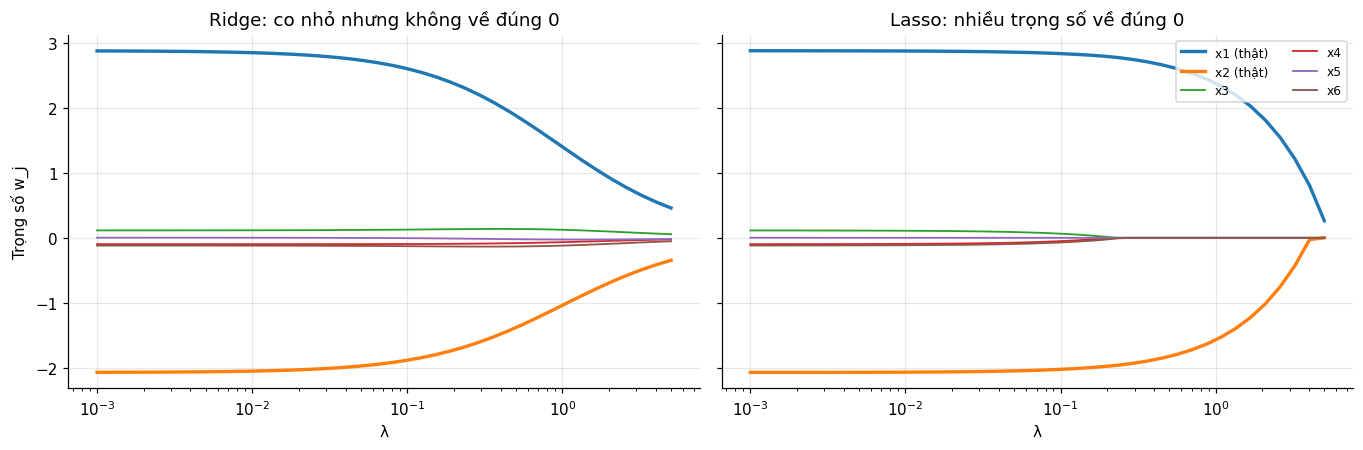

Lasso với λ = 0.5: {'x1 (thật)': 2.636, 'x2 (thật)': -1.826, 'x3': 0.0, 'x4': 0.0, 'x5': 0.0, 'x6': 0.0}


In [18]:
from sklearn.linear_model import Lasso, Ridge
r9 = np.random.default_rng(3)
n9 = 200
Xt = r9.normal(size=(n9, 6))
y9 = 3.0 * Xt[:, 0] - 2.0 * Xt[:, 1] + r9.normal(0, 1.0, n9)     # chỉ 2 đặc trưng đầu có tác dụng
ten_dt = ["x1 (thật)", "x2 (thật)", "x3", "x4", "x5", "x6"]

lams9 = np.logspace(-3, 0.7, 40)
W_l = np.array([Lasso(alpha=l / 2).fit(Xt, y9).coef_ for l in lams9])      # alpha = λ/2
W_r = np.array([Ridge(alpha=n9 * l).fit(Xt, y9).coef_ for l in lams9])     # alpha = nλ

fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.2), sharey=True)
for ax, Wm, t in [(axs[0], W_r, "Ridge: co nhỏ nhưng không về đúng 0"), (axs[1], W_l, "Lasso: nhiều trọng số về đúng 0")]:
    for j in range(6): ax.semilogx(lams9, Wm[:, j], label=ten_dt[j], lw=2.2 if j < 2 else 1.2)
    ax.set_xlabel("λ"); ax.set_title(t)
axs[0].set_ylabel("Trọng số w_j"); axs[1].legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()
l_xem = 0.5
print(f"Lasso với λ = {l_xem}:", {k: round(float(v), 3) + 0.0 for k, v in zip(ten_dt, Lasso(alpha=l_xem / 2).fit(Xt, y9).coef_)})

## 10. Dữ liệu lớn hơn: huấn luyện và đánh giá (mục 6.2 của tài liệu)

Dữ liệu 300 căn nhà ở mục 6 sinh theo quan hệ thật `y = 0,8 + 0,045·x₁ − 0,08·x₂ + nhiễu (σ = 0,4)`. Vì biết quan hệ thật nên ta kiểm tra được mô hình có **tìm lại** các hệ số hay không.

In [19]:
w_gd, J = huan_luyen_gd(Xs_tr, y_tr, eta=0.1, t_max=5000, eps=1e-12)
w_pt = phuong_trinh_chuan(Xs_tr, y_tr)
print("GD: số lần lặp =", len(J) - 1, "| w =", np.round(w_gd, 4))
print("PT chuẩn        | w =", np.round(w_pt, 4))
print("Sai khác tối đa giữa hai nghiệm: %.2e" % np.max(np.abs(w_gd - w_pt)))

w1_g = w_pt[1:] / sd
w0_g = w_pt[0] - np.sum(w_pt[1:] * tb / sd)
print("Hệ số trên thang đo gốc: w0 = %.4f, w1 = %.4f, w2 = %.4f" % (w0_g, *w1_g))
print("Quan hệ thật           : w0 = 0.8000, w1 = 0.0450, w2 = -0.0800")

GD: số lần lặp = 68 | w = [ 3.4679  1.1855 -0.3627]
PT chuẩn        | w = [ 3.4679  1.1855 -0.3627]
Sai khác tối đa giữa hai nghiệm: 8.92e-07
Hệ số trên thang đo gốc: w0 = 0.8157, w1 = 0.0452, w2 = -0.0871
Quan hệ thật           : w0 = 0.8000, w1 = 0.0450, w2 = -0.0800


### Các thước đo đánh giá

$$\text{MSE}=\tfrac1n\sum e_i^2,\quad \text{RMSE}=\sqrt{\text{MSE}},\quad \text{MAE}=\tfrac1n\sum|e_i|,\quad R^2=1-\frac{\sum e_i^2}{\sum (y_i-\bar y)^2}$$

`R² = 1` là hoàn hảo, `R² = 0` là không hơn việc luôn đoán trung bình, `R² < 0` là còn tệ hơn.

Huấn luyện: MSE = 0.1732 | RMSE = 0.4162 | MAE = 0.3340 | R2 = 0.8958
Kiểm tra  : MSE = 0.1526 | RMSE = 0.3907 | MAE = 0.2995 | R2 = 0.9008
Baseline (đoán y trung bình): R2 trên tập kiểm tra = -0.0000


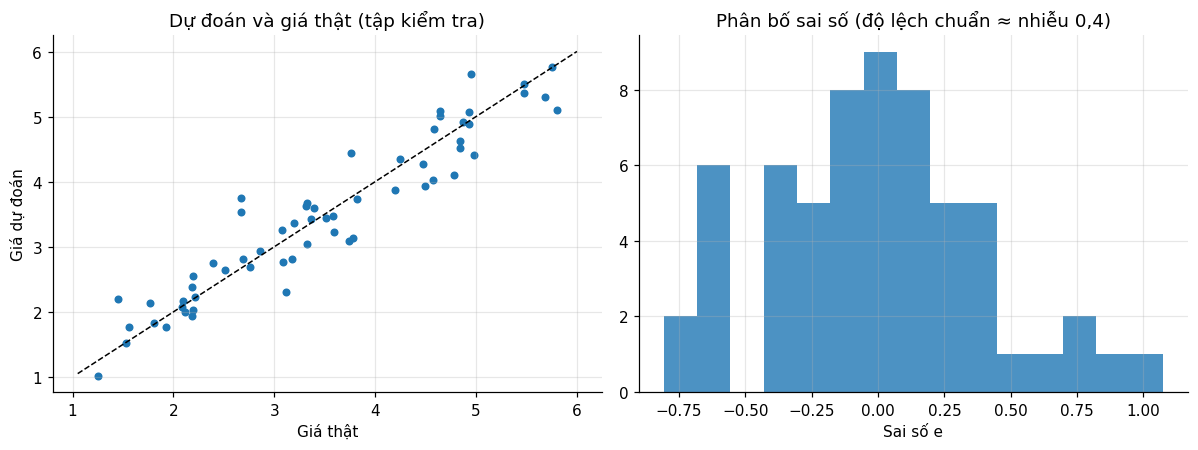

In [20]:
def danh_gia(y, y_hat):
    e = y_hat - y
    mse_ = np.mean(e ** 2)
    mae_ = np.mean(np.abs(e))
    r2 = 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2)
    return mse_, np.sqrt(mse_), mae_, r2

for ten, Xm, ym in [("Huấn luyện", Xs_tr, y_tr), ("Kiểm tra  ", Xs_te, y_te)]:
    m, r, a, r2 = danh_gia(ym, du_doan(Xm, w_pt))
    print("%s: MSE = %.4f | RMSE = %.4f | MAE = %.4f | R2 = %.4f" % (ten, m, r, a, r2))
print("Baseline (đoán y trung bình): R2 trên tập kiểm tra = %.4f" % danh_gia(y_te, np.full(len(y_te), y_tr.mean()))[3])

y_hat_te = du_doan(Xs_te, w_pt)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
axs[0].scatter(y_te, y_hat_te, s=18); lim = [y_te.min() - .2, y_te.max() + .2]
axs[0].plot(lim, lim, "k--", lw=1); axs[0].set_xlabel("Giá thật"); axs[0].set_ylabel("Giá dự đoán"); axs[0].set_title("Dự đoán và giá thật (tập kiểm tra)")
axs[1].hist(y_hat_te - y_te, bins=15, color="tab:blue", alpha=0.8); axs[1].set_xlabel("Sai số e"); axs[1].set_title("Phân bố sai số (độ lệch chuẩn ≈ nhiễu 0,4)")
plt.tight_layout(); plt.show()

### Ridge cài từ đầu trên bộ 300 căn nhà

Ở bài toán này mô hình đã đúng dạng và dữ liệu nhiều (240 mẫu cho 3 tham số) nên **không có quá khớp để chữa**: điều chuẩn chỉ làm mô hình bị thiếu khớp, MSE kiểm tra **tăng** theo λ. Điều chuẩn có ích khi mô hình phức tạp hơn dữ liệu (như đa thức bậc 9 ở mục 9).

In [21]:
for lam in [0, 0.1, 1, 10]:
    w_r = ridge(Xs_tr, y_tr, lam)
    print("lambda = %-4s w = %s | MSE kiểm tra = %.4f" % (lam, np.round(w_r, 4), danh_gia(y_te, du_doan(Xs_te, w_r))[0]))

lambda = 0    w = [ 3.4679  1.1855 -0.3627] | MSE kiểm tra = 0.1526
lambda = 0.1  w = [ 3.4679  1.0758 -0.3241] | MSE kiểm tra = 0.1625
lambda = 1    w = [ 3.4679  0.5872 -0.1645] | MSE kiểm tra = 0.5034
lambda = 10   w = [ 3.4679  0.1061 -0.0274] | MSE kiểm tra = 1.3018


## 11. So sánh với scikit-learn (mục 6.3 của tài liệu)

Lưu ý quy ước tham số điều chuẩn khác nhau: Ridge của sklearn tối thiểu `‖y−Xw‖² + α‖w‖²` (không chia n) nên `α = nλ`; Lasso tối thiểu `(1/2n)‖y−Xw‖² + α‖w‖₁` nên `α = λ/2`.

In [22]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

n_tr = len(y_tr)
lam = 0.1
mo_hinh = {
    "LinearRegression": LinearRegression(),
    "Ridge (lambda=0,1)": Ridge(alpha=n_tr * lam),
    "Lasso (lambda=0,1)": Lasso(alpha=lam / 2),
    "SGDRegressor": SGDRegressor(loss="squared_error", penalty=None, learning_rate="constant",
                                 eta0=0.01, max_iter=2000, tol=1e-6, random_state=0),
}
print("%-20s %-28s %-9s %-9s %-7s" % ("Mô hình", "Hệ số (thang chuẩn hóa)", "MSE", "MAE", "R2"))
for ten, m in mo_hinh.items():
    pipe = make_pipeline(StandardScaler(), m).fit(X_tr, y_tr)
    y_hat = pipe.predict(X_te)
    h = pipe[-1]
    print("%-20s b=%.3f w=%s %.4f    %.4f    %.4f" % (ten, float(np.ravel(h.intercept_)[0]), np.round(h.coef_, 3),
          mean_squared_error(y_te, y_hat), mean_absolute_error(y_te, y_hat), r2_score(y_te, y_hat)))

print("\nSo với tự cài đặt: PT chuẩn w =", np.round(w_pt, 3), "| Ridge (λ=0,1) w =", np.round(ridge(Xs_tr, y_tr, 0.1), 3))

Mô hình              Hệ số (thang chuẩn hóa)      MSE       MAE       R2     
LinearRegression     b=3.468 w=[ 1.186 -0.363] 0.1526    0.2995    0.9008
Ridge (lambda=0,1)   b=3.468 w=[ 1.076 -0.324] 0.1625    0.3157    0.8944
Lasso (lambda=0,1)   b=3.468 w=[ 1.133 -0.31 ] 0.1587    0.3096    0.8968
SGDRegressor         b=3.484 w=[ 1.215 -0.378] 0.1539    0.3027    0.8999

So với tự cài đặt: PT chuẩn w = [ 3.468  1.186 -0.363] | Ridge (λ=0,1) w = [ 3.468  1.076 -0.324]


**Nhận xét**

- `LinearRegression` cho đúng nghiệm phương trình chuẩn tự cài đặt (hệ số chệch lưu ở `intercept_`, trọng số ở `coef_`).
- Ridge với `α = nλ` **trùng** kết quả `ridge()` tự cài đặt.
- `SGDRegressor` cho kết quả **gần nhưng không trùng** nghiệm chính xác vì mỗi bước chỉ dùng gradient của một mẫu.
- Với dữ liệu nhỏ, đơn giản như thế này, dùng `LinearRegression` là đủ.

## Bài tập tự làm

1. Ở mục 2, thêm một đường thẳng của bạn vào `duong` và thử tìm đường có `J` nhỏ hơn 0,03 bằng cách chỉnh tay. So với `J(w*) = 0,023`.
2. Ở mục 4.5, thử `η = 0,0358` và `η = 0,036`. Quan sát điều gì xảy ra quanh ngưỡng ổn định?
3. Ở mục 6, thử tăng `η` của SGD lên 0,05 và nhận xét về độ dao động.
4. Ở mục 7, giảm số điểm huấn luyện xuống 6 (trong `sinh_du_lieu(10, ...)`) và xem quá khớp thay đổi thế nào.
5. Ở mục 8, đổi `y_ngoai` từ 3 đến 9 và quan sát hai đường MSE và MAE.
6. Ở mục 9.2, thử `l_xem` bằng 0,05; 0,5; 2. Từ giá trị nào Lasso loại hết đặc trưng nhiễu?